In [12]:
%load_ext autoreload
%autoreload 2

In [13]:
from pylab import *
import numpy as np
from visualization import complexToRGB


# Load some frames

In [3]:
#batch_frame_path = "C:\\Users\\ModeLabQBI\\LAB\\algorithms\\DigitalHolography\\data_testing\\Aligment_batch_frames_z=0_ref_BEST.npz"
batch_frame_path = "C:\\Users\\ModeLabQBI\\LAB\\algorithms\\DigitalHolography\\data_testing\\Aligment_batch_frames_SLM_relayed_modes.npz"
batch_frame_path = "C:\\Users\\ModeLabQBI\\LAB\\algorithms\\DigitalHolography\\data_testing\\Aligment_batch_frames.npz"

keys: ['frames']
frames (506, 512, 640) float32 min 0.0 max 4095.0


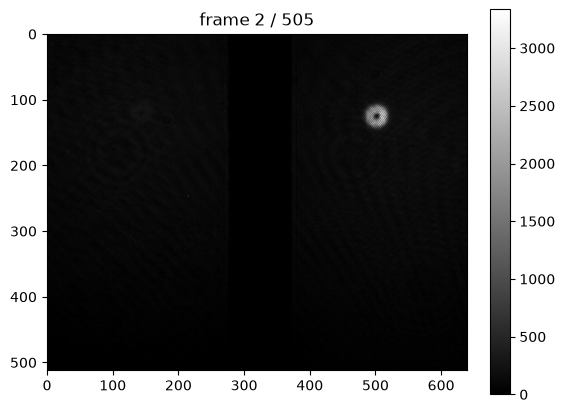

In [4]:
npz_path = batch_frame_path
with np.load(npz_path) as data:
    frames = data["frames"]
    print( "keys:", list(data.files))

print("frames", frames.shape, frames.dtype, "min", float(frames.min()), "max", float(frames.max()))

frame_index = 2
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(frames[frame_index], cmap="gray")
ax.set_title(f"frame {frame_index} / {frames.shape[0] - 1}")
fig.colorbar(image, ax=ax, fraction=0.046)
plt.show()

In [5]:
_batch_dim = frames.shape
num_frames = _batch_dim[0]
frame_width = _batch_dim[2]
frame_height = _batch_dim[1]
print(f'{num_frames} frames of {frame_width}x{frame_height} pixels (WxH)')

506 frames of 640x512 pixels (WxH)


# Digholo

In [7]:
from pathlib import Path
import sys

root = Path.cwd().resolve().parent
sys.path.insert(0, str(root))

from pyDigHolo import DigHolo

In [8]:
dh = DigHolo()

In [9]:
512, 640

(512, 640)

In [10]:
dh.setProps(PixelSize=20e-6, Wavelength=1310e-9, polCount=2, maxMG=22,
fftWindowSizeX =  128,
fftWindowSizeY =  128,
basisType = 0,
goalIdx = 0,
#FFTRadius = 0.8,
resolutionMode = 0,
verbosity=2)

In [11]:
dh.save_properties_to_json("relayed_modes_test_Cheetah_Xenics.json")

In [12]:
frames.dtype

dtype('float32')

In [ ]:
#frames_h = np.ascontiguousarray(np.transpose(frames, (0, 2, 1)))
frames_h = np.ascontiguousarray(frames, dtype=np.float32)
#frames_h = flip(frames_h, axis=2)
coefs, metrics = dh.autoAlign(frames_h)

In [14]:
frames_h.shape

(506, 512, 640)

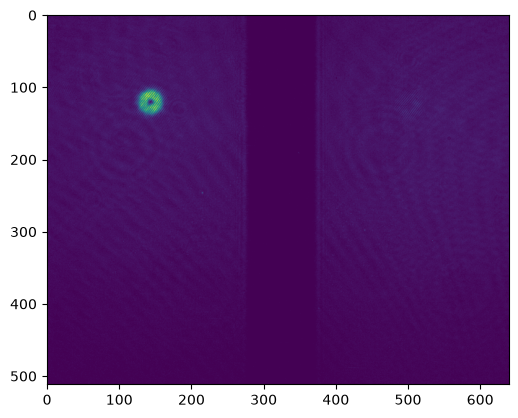

In [15]:
imshow(frames_h[3])

In [16]:
coefs_interleaved = zeros_like(coefs)

coefs_h = coefs[:, 0:coefs.shape[1]//2]
coefs_v = coefs[:, coefs.shape[1]//2:]

coefs_interleaved[:,::2] = coefs_h
coefs_interleaved[:,1::2] = coefs_v

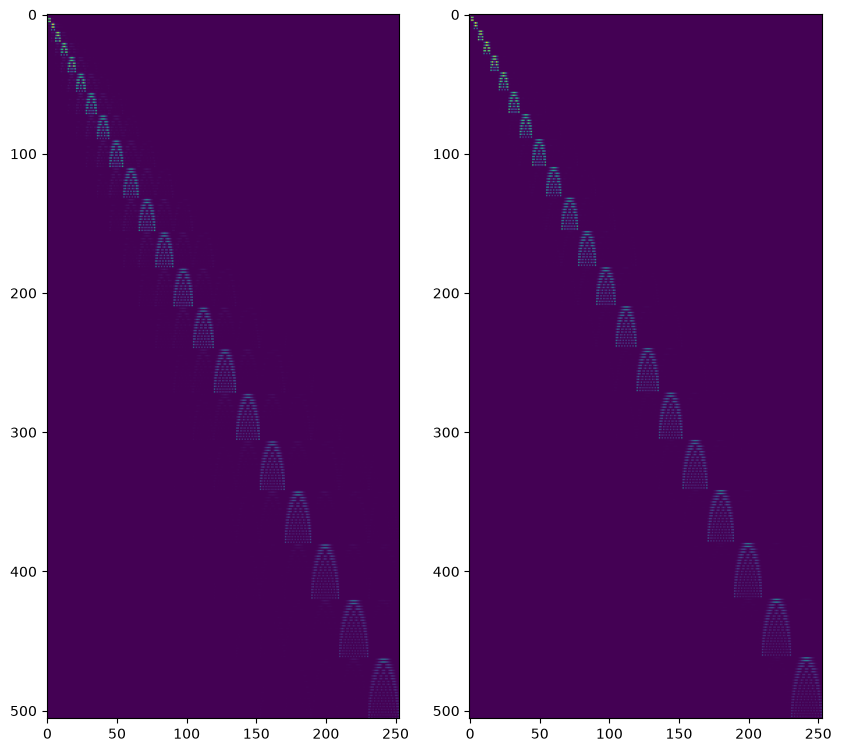

In [17]:
fig, ax = subplots(1,2, figsize=(10,10))
ax[0].imshow(abs(coefs_h)**2)
ax[1].imshow(abs(coefs_v)**2)

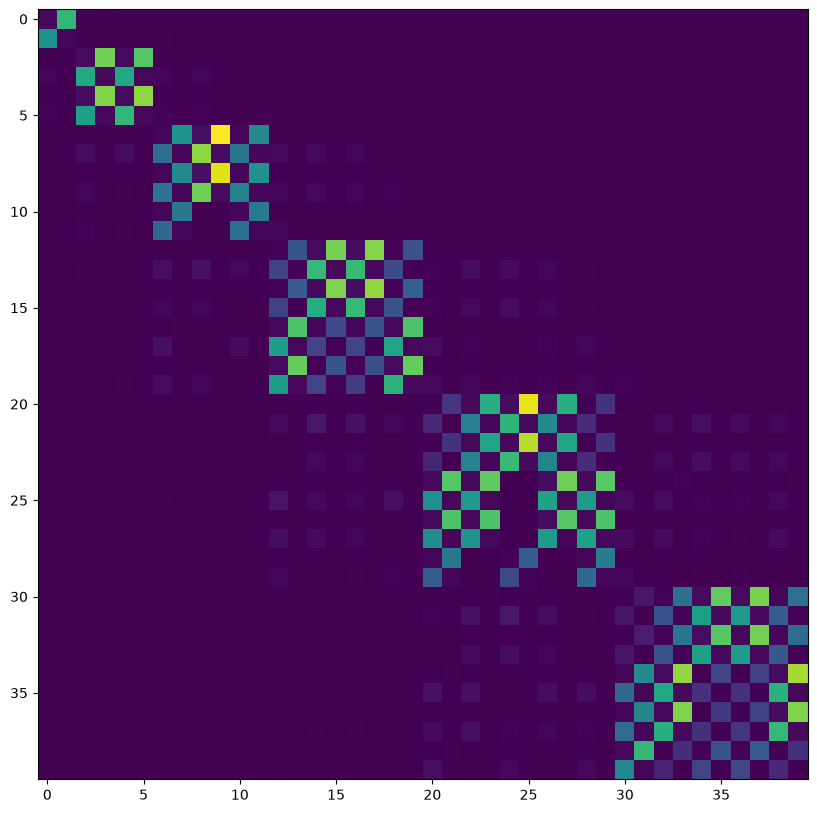

In [18]:
figure(figsize=(10,10))
imshow(abs(coefs_interleaved[0:40,0:40])**2)

In [19]:
coefs = dh.processBatch(frames_h[None, 1,...], batchCount=1)

In [20]:
fields = dh.getFields()

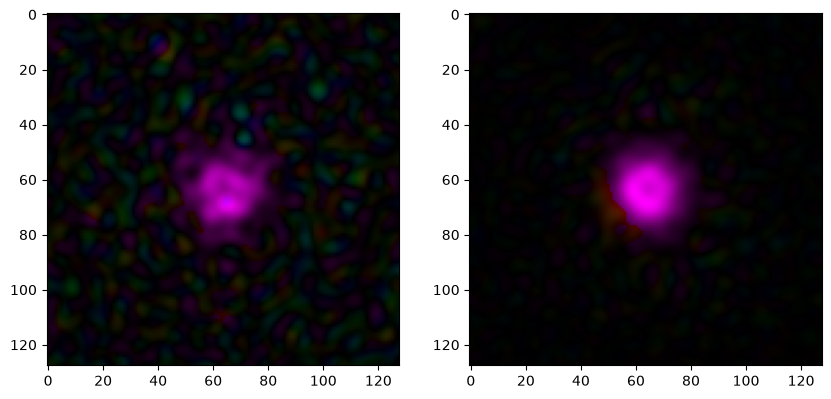

In [21]:
fig, ax = subplots(1,2, figsize=(10,10))
ax[0].imshow(complexToRGB(fields[0,1]))
ax[1].imshow(complexToRGB(fields[0,0]))


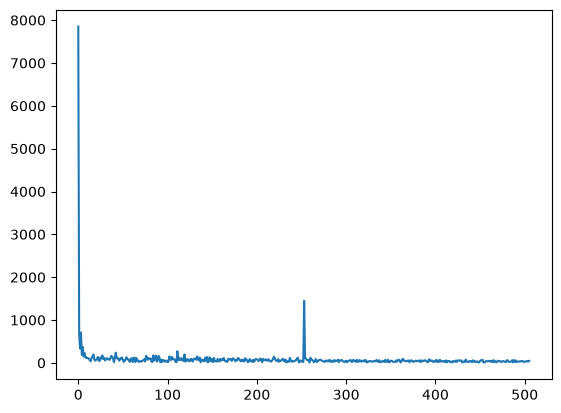

In [22]:
plot(abs(coefs[0]))

In [ ]:
import ipywidgets as widgets

viewport_names = {
    1: "camera",
    2: "Fourier",
    3: "Fourier dB",
    4: "Fourier window",
    5: "Fourier window abs",
    6: "field",
    7: "field abs",
    8: "field from modes",
}

def show_viewport(viewport_idx, frame_index):
    dh.processBatch(frames_h[None, frame_index, ...], batchCount=1)
    img, metadata = dh.getViewPort(viewport_idx)
    fig, ax = plt.subplots(figsize=(12, 10))
    ax.imshow(img)
    ax.set_title(
        f"frame {frame_index} / {frames_h.shape[0] - 1}   "
        f"viewport {viewport_idx}: {viewport_names[viewport_idx]}\n{metadata}"
    )
    plt.show()

widgets.interact(
    show_viewport,
    viewport_idx=widgets.IntSlider(min=1, max=8, step=1, value=1, continuous_update=False),
    frame_index=widgets.IntSlider(min=0, max=frames_h.shape[0] - 1, step=1, value=0, continuous_update=False),
)

interactive(children=(IntSlider(value=1, continuous_update=False, description='viewport_idx', max=8, min=1), I…

<function __main__.show_viewport(viewport_idx, frame_index)>

In [ ]:
from matplotlib.patches import Circle
import ipywidgets as widgets

px = 20e-6
h, w = frames_h.shape[1:]

def show_frame(frame_index):
    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(frames_h[frame_index], cmap="gray")
    for pol, color in (("PolH", "r"), ("PolV", "c")):
        col = dh._properties[f"BeamCentreX{pol}"] / px + (w - 1) / 2
        row = dh._properties[f"BeamCentreY{pol}"] / px + (h - 1) / 2
        radius = dh._properties[f"BasisWaist{pol}"] / px
        ax.plot(col, row, "+", color=color, ms=12)
        ax.add_patch(Circle((col, row), radius, fill=False, ec=color, lw=1.5))
    ax.set_title(f"frame {frame_index} / {frames_h.shape[0] - 1}")
    plt.show()

widgets.interact(show_frame, frame_index=(0, frames_h.shape[0] - 1, 1))

interactive(children=(IntSlider(value=252, description='frame_index', max=505), Output()), _dom_classes=('widg…

<function __main__.show_frame(frame_index)>

# Hook digholo to a Camera for live processing:

## DigHolo Init

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pylab import *
import numpy as np
from visualization import complexToRGB

In [3]:
from pathlib import Path
import sys

root = Path.cwd().resolve().parent
sys.path.insert(0, str(root))

from pyDigHolo import DigHolo

In [4]:
dh = DigHolo()

In [5]:
dh.setProps(PixelSize=6.9e-6, Wavelength = 843.5e-9, polCount=2, maxMG=22,
fftWindowSizeX =  64,
fftWindowSizeY =  64,
basisType = 0,
goalIdx = 0,
#FFTRadius = 0.8,
resolutionMode = 0,
verbosity=2)

## Camera init

In [6]:
from cameras.alliedvision import VimbaXInterface, VimbaXCamera

In [7]:
iface = VimbaXInterface()

Camera 0:
--------------------------------
 id     : DEV_1AB22C0B85AF
 name   : Allied Vision 1800 U-040m
 model  : 1800 U-040m
 serial : 0G6NJ
 interface : VimbaUSBInterface_0x0
 interface type : TransportLayerType.U3V
 transport layer : AVT USB Transport Layer
 transport layer type: TransportLayerType.U3V
--------------------------------
Camera 1:
--------------------------------
 id     : DEV_1AB22C0B85B0
 name   : Allied Vision 1800 U-040m
 model  : 1800 U-040m
 serial : 0G6NK
 interface : VimbaUSBInterface_0x0
 interface type : TransportLayerType.U3V
 transport layer : AVT USB Transport Layer
 transport layer type: TransportLayerType.U3V
--------------------------------
Camera 2:
--------------------------------
 id     : DEV_Cam1
 name   : Allied Vision Camera Simulator (G1-030_VSWIR)(DEV_Cam1)
 model  : Camera Simulator (G1-030_VSWIR)
 serial : 0D512
 interface : Camera Simulator Interface
 interface type : TransportLayerType.Custom
 transport layer : Camera Simulator TL
 transp

In [8]:
CAM_INDEX = 0  # change as needed
raw = iface._cameras_found[CAM_INDEX]
cam = VimbaXCamera(raw, ring_buffer_size =  100)
cam

VimbaXCamera(id='DEV_1AB22C0B85AF', name='Allied Vision 1800 U-040m', serial='0G6NJ', device_name='ALVIUM')

In [9]:
%gui qt

In [10]:
from cameras import pyVimbaX
from cameras.ui import CameraViewport

In [11]:


viewport_cam = pyVimbaX(cam)
viewport_cam.open()
viewport = CameraViewport(viewport_cam)
viewport.show()
viewport.start()
print("viewport started — use Start/Stop in the window, or run the next cell to stop")

viewport started — use Start/Stop in the window, or run the next cell to stop


In [12]:
from pyDigHolo import DigHoloFeeder

uint8
544 720


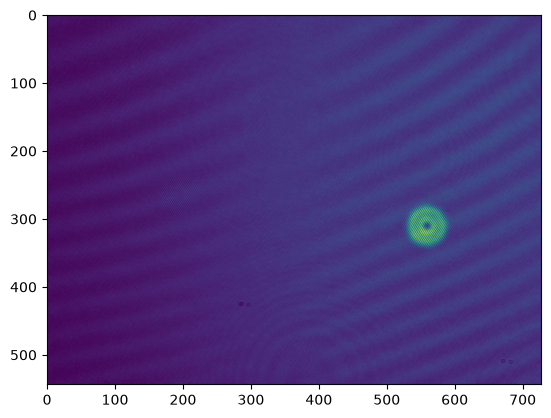

In [13]:
frame, _ = cam.get_tail(1)
print(frame.dtype)
frame_H = frame.shape[1]
frame_W = frame.shape[2]

if frame_H % 16 != 0:
    frame_H = frame_H - frame_H % 16
if frame_W % 16 != 0:
    frame_W = frame_W - frame_W % 16
    
print(frame_H, frame_W)
imshow(frame[0])

In [14]:
544  / 16

34.0

In [15]:
dh.setProps(FrameWidth=frame_W, FrameHeight=frame_H, fftWindowSizeX  = 128, fftWindowSizeY =  128 , FFTRadius = 0.5)

In [16]:
dh.getProps()

{'Wavelength': 8.435000040662999e-07,
 'WavelengthCount': 1,
 'polCount': 2,
 'batchCount': 1,
 'AvgCount': 1,
 'PixelSize': 6.9e-06,
 'maxMG': 22,
 'FrameWidth': 720,
 'FrameHeight': 544,
 'fftWindowSizeX': 128,
 'fftWindowSizeY': 128,
 'FFTRadius': 0.5,
 'BeamCentreXPolH': 0.0,
 'BeamCentreXPolV': 0.0,
 'BeamCentreYPolH': 0.0,
 'BeamCentreYPolV': 0.0,
 'BasisWaistPolH': 1.0,
 'BasisWaistPolV': 1.0,
 'DefocusPolH': 0.0,
 'DefocusPolV': 0.0,
 'XTiltPolH': 0.0,
 'XTiltPolV': 0.0,
 'YTiltPolH': 0.0,
 'YTiltPolV': 0.0,
 'AutoAlignBeamCentre': 1,
 'AutoAlignDefocus': 1,
 'AutoAlignTilt': 1,
 'AutoAlignBasisWaist': 1,
 'AutoAlignFourierWindowRadius': 1,
 'goalIdx': 0,
 'basisType': 0,
 'resolutionMode': 0,
 'verbosity': 2}

In [17]:
px_pitch = 6.9e-6

In [18]:
beamHposX = 197 
beamHposY = 260 
beamVposX = 559 
beamVposY = 310 
beamHposX = (beamHposX - frame_W / 2) * px_pitch
beamHposY = (beamHposY - frame_H / 2) * px_pitch
beamVposX = (beamVposX - frame_W / 2) * px_pitch
beamVposY = (beamVposY - frame_H / 2) * px_pitch


In [19]:
dh.setProps(BeamCentreXPolH = beamHposX, BeamCentreYPolH = beamHposY, BeamCentreXPolV =beamVposX, BeamCentreYPolV = beamVposY)

In [20]:
dh.setProps(
    XTiltPolH=2.2, YTiltPolH=-1.3,
    XTiltPolV=2.2, YTiltPolV=-1.5,
)

In [21]:
frame, _ = cam.get_tail(1)
frame = frame[:, 0:frame_H, 0:frame_W]
held = np.ascontiguousarray(frame, dtype=np.float32)  # shape (1, H, W)
coefs = dh.processBatch(held, batchCount=1)


In [22]:
dhStreamer = DigHoloFeeder(dh_Object = dh, cam_Object = cam, cam_grab_ufunc_name = "get_tail", averaging = 1, startStream = True, refresh_rate_fps =  30)

In [23]:
dhStreamer._error_message

In [30]:
dhStreamer.set_averaging(20)

In [25]:
dhStreamer.get_processing_stats()

(866.5510844833212, 30.0)

In [26]:

import ipywidgets as widgets

viewport_names = {
    1: "camera",
    2: "Fourier",
    3: "Fourier dB",
    4: "Fourier window",
    5: "Fourier window abs",
    6: "field",
    7: "field abs",
    8: "field from modes",
}

def show_viewport(viewport_idx):
    img, metadata = dh.getViewPort(viewport_idx)
    fig, ax = plt.subplots(figsize=(12, 10))
    ax.imshow(img)
    ax.set_title(
        f"viewport {viewport_idx}: {viewport_names[viewport_idx]}\n{metadata}"
    )
    plt.show()

widgets.interact(
    show_viewport,
    viewport_idx=widgets.IntSlider(min=1, max=8, step=1, value=1, continuous_update=False),
)

interactive(children=(IntSlider(value=1, continuous_update=False, description='viewport_idx', max=8, min=1), O…

<function __main__.show_viewport(viewport_idx)>

In [ ]:
from pyDigHolo.ui import DigHoloViewport

vp = DigHoloViewport(dh, refresh_rate_fps=33)
vp.show()
vp.start()

In [152]:
dhStreamer.pause()

In [158]:
dhStreamer.kill()

In [187]:
frame, _ = cam.get_tail(1)
frame = frame[:, 0:frame_H, 0:frame_W]
held = np.ascontiguousarray(frame, dtype=np.float32)  # shape (1, H, W)
coefs = dh.processBatch(held, batchCount=1)

In [188]:
img, metadata = dh.getViewPort(1)
imshow(img)





OSError: exception: access violation reading 0x0000018D2CF5E040